# 02 – Descriptive Statistics by Asset

## Context
This notebook is part of a project on the effect of diversification in a portfolio.
Before studying the assets together, it analyses the behaviour of each one separately.

## Data
- **File:** `Data/Processed/dataset_clean.csv`, produced by `01_data_collection.ipynb`
- **Source:** Yahoo Finance, via `yfinance`
- **Assets:** GLD, ASML.AS, TTE.PA, AI.PA, MC.PA, IWDA.AS and BTC-USD
- **Period:** rolling 5 years
- **Prices:** adjusted closing prices, converted to USD to reflect the point of view of a USD-based investor
- **Dates kept:** only the days when all assets have a price, which avoids the artificial flat days created by filling gaps
- **Columns:** asset prices only, as exchange rates are removed in notebook 01 and must not enter the statistics

## Contents
1. Normalised price evolution (base 100)
2. Daily, total and annualised returns
3. Daily and annualised volatility
4. Return / risk ratio
5. Maximum drawdown
6. Comparative summary of the assets

## Setup

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

## Data loading
The dataset was cleaned in notebook 01, so it is only loaded here.
Asset names are retrieved from Yahoo Finance to make the results easier to read.

=== Assets ===
  AI.PA      AIR LIQUIDE
  ASML.AS    ASML HOLDING
  BTC-USD    Bitcoin USD
  GLD        SPDR Gold Shares
  IWDA.AS    iShares Core MSCI World UCITS E
  MC.PA      LVMH
  TTE.PA     TOTALENERGIES

=== Dataset overview ===
Number of assets      : 7
Number of rows        : 1242
Missing values        : 0

=== Period covered ===
Start                 : 01/11/2021
End                   : 30/10/2026
Duration              : 4.99 years
Trading days/year     : 249


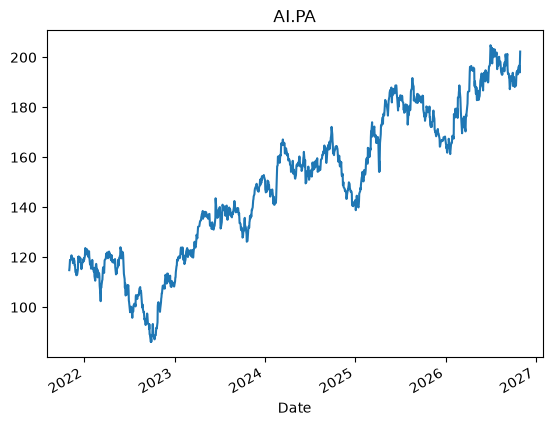

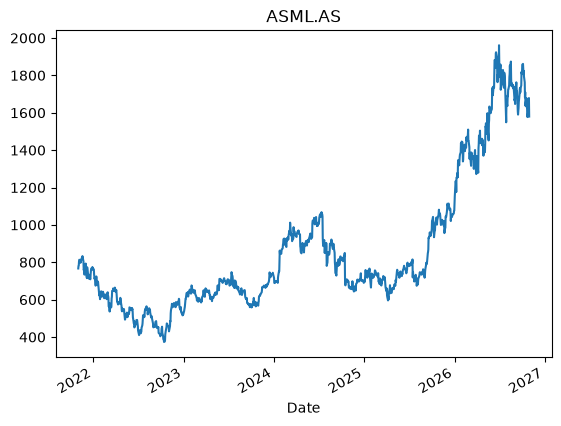

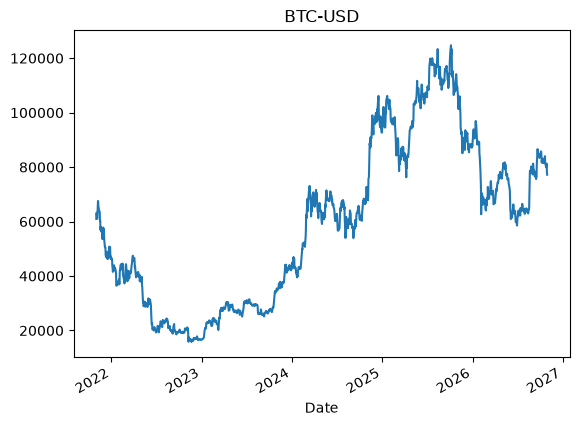

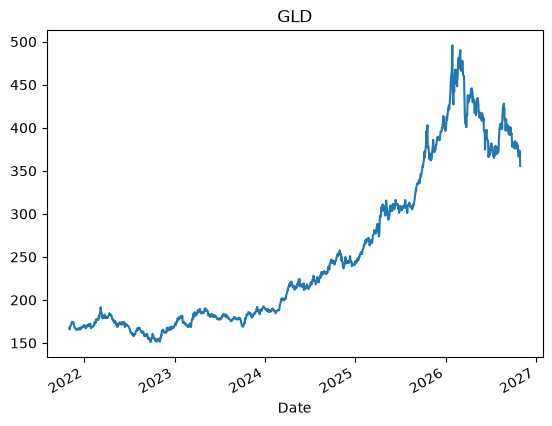

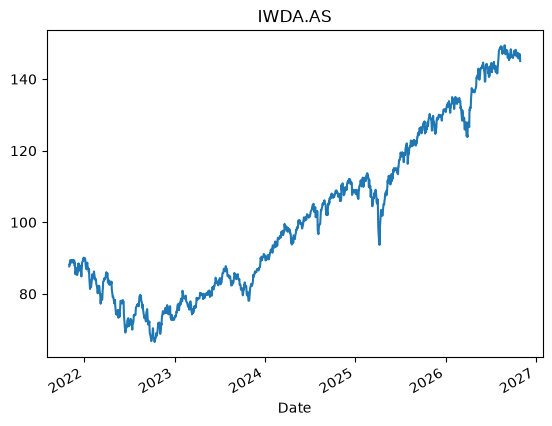

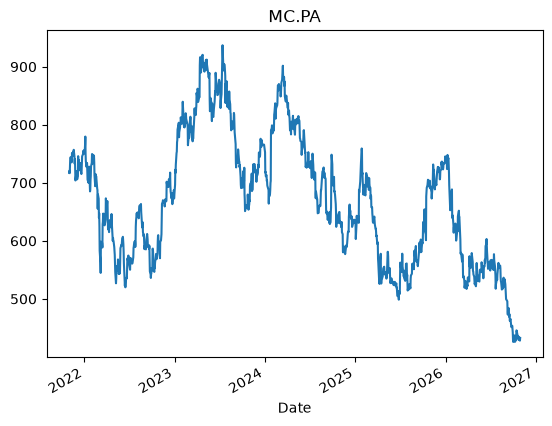

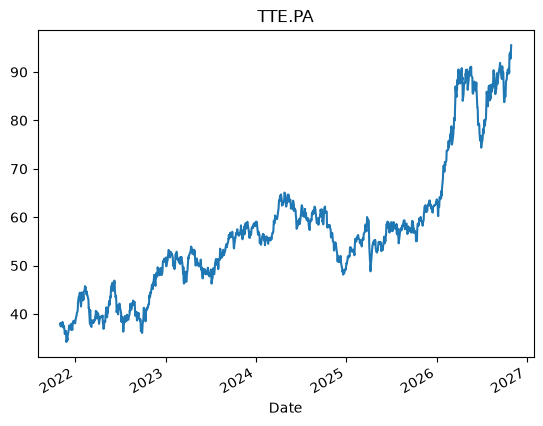

In [11]:
df = pd.read_csv("../Data/Processed/dataset_clean.csv", index_col='Date', parse_dates=True)

name_by_ticker = {}
for ticker in df.columns:
    info = yf.Ticker(ticker).info
    name_by_ticker[ticker] = info.get("shortName", ticker)

n_rows, n_assets = df.shape
start, end = df.index.min(), df.index.max()
n_years = (end - start).days / 365.25

print("=== Assets ===")
for ticker, name in name_by_ticker.items():
    print(f"  {ticker:<10} {name}")

print("\n=== Dataset overview ===")
print(f"{'Number of assets':<22}: {n_assets}")
print(f"{'Number of rows':<22}: {n_rows}")
print(f"{'Missing values':<22}: {df.isna().sum().sum()}")

print("\n=== Period covered ===")
print(f"{'Start':<22}: {start:%d/%m/%Y}")
print(f"{'End':<22}: {end:%d/%m/%Y}")
print(f"{'Duration':<22}: {n_years:.2f} years")
print(f"{'Trading days/year':<22}: {n_rows / n_years:.0f}")


for elem in df.columns:
    df[elem].plot(title=elem)
    plt.show()

## Price normalisation
Each price series starts at 100, so assets with very different price levels can be compared on the same chart.

                 AI.PA     ASML.AS     BTC-USD         GLD     IWDA.AS  \
Date                                                                     
2021-11-01  100.000000  100.000000  100.000000  100.000000  100.000000   
2021-11-02  100.813965  101.815798  103.642353   99.785100  100.734977   
2021-11-03  102.033933  102.013897  103.222129   98.955349  100.533592   
2021-11-04  103.531689  104.879902  100.734085  100.077596  101.888779   
2021-11-05  103.337944  106.075840  100.198788  101.384904  101.912441   

                 MC.PA      TTE.PA  
Date                                
2021-11-01  100.000000  100.000000  
2021-11-02  100.576798  100.705517  
2021-11-03  100.064890   98.769736  
2021-11-04  101.849496   99.864579  
2021-11-05  103.719356   99.712827  


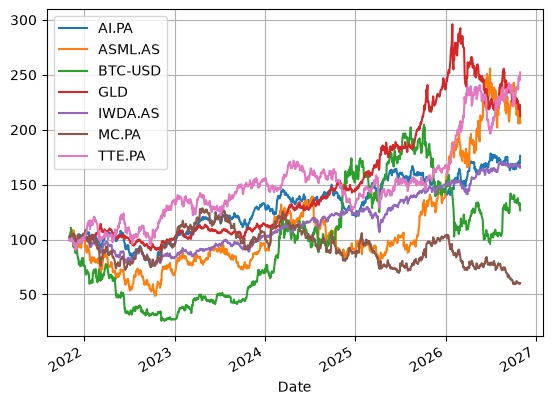

In [12]:
def normalise_prices (prices):
    return prices / prices.iloc[0] * 100

normalised_prices = normalise_prices(df)
print(normalised_prices.head())
normalised_prices. plot(grid=True)
plt.show()

## Returns
- **Daily return:** percentage change between two consecutive rows. As only common trading days are kept, two consecutive rows can be several calendar days apart.
- **Total return:** daily returns compounded over the whole period.
- **Annual return:** constant yearly growth rate that gives the total return over the actual length of the period.

In [13]:
## Returns a DataFrame with the daily return of each column (excluding the index)
def compute_daily_returns(prices):
    previous_prices = prices.shift(1)
    returns = (prices - previous_prices) / previous_prices
    return returns.dropna() # a DataFrame

daily_returns = compute_daily_returns(normalised_prices)

## Total performance of each asset
def compute_total_returns(daily_returns):
    return (1 + daily_returns).prod() - 1 # performance over the whole DataFrame period

total_returns = compute_total_returns(daily_returns)  # a Series

print(f"=== Perf over {round(n_years)} years ===\n")
for ticker,total_return_pct  in total_returns.sort_values(ascending=False).items():
    name = name_by_ticker[ticker]
    
    if total_return_pct>0 :
        print(f"{name} : +{round(total_return_pct*100, 2)}%")
    else : 
        print(f"{name} : {round(total_return_pct*100, 2)}%")


def compute_annual_returns(total_returns, n_years) :
    return (1+total_returns)**(1/n_years)-1

annual_return = compute_annual_returns(total_returns,n_years)

print(f"\n=== Annual return over {round(n_years)} years ===\n")
for ticker, an_return in annual_return.sort_values(ascending=False).items() : 
    name = name_by_ticker[ticker]
    print(f"{name} : {round(an_return*100,2)}%/year")



=== Perf over 5 years ===

TOTALENERGIES : +152.16%
SPDR Gold Shares : +112.38%
ASML HOLDING : +106.02%
AIR LIQUIDE : +76.18%
iShares Core MSCI World UCITS E : +65.41%
Bitcoin USD : +26.55%
LVMH : -39.63%

=== Annual return over 5 years ===

TOTALENERGIES : 20.35%/year
SPDR Gold Shares : 16.28%/year
ASML HOLDING : 15.57%/year
AIR LIQUIDE : 12.01%/year
iShares Core MSCI World UCITS E : 10.6%/year
Bitcoin USD : 4.83%/year
LVMH : -9.61%/year


## Volatility
Daily volatility is the standard deviation of daily returns.
It is annualised by multiplying it by the square root of the number of rows per year.
This number is measured from the dataset instead of using the usual 252 days, because only the days common to all assets are kept.

In [14]:
def compute_daily_volatility(daily_returns):
    return daily_returns.std()

daily_volatility = compute_daily_volatility(daily_returns)

print(f"=== Daily volatility (data over {round(n_years)} years) per day ===\n")
for ticker, volatility in daily_volatility.sort_values(ascending=False).items():
    name = name_by_ticker[ticker]
    print(f"{name} : {round(volatility*100, 2)}%")

def compute_annual_volatility(daily_volatility, lines_per_year) :
    return daily_volatility*lines_per_year**0.5

lines_per_year = n_rows / n_years

annual_volatility = compute_annual_volatility(daily_volatility, lines_per_year) 

print(f"\n=== Annual volatility (data over {round(n_years)} years)===\n")
for ticker, volatility in annual_volatility.sort_values(ascending=False).items():
    name = name_by_ticker[ticker]
    print(f"{name} : {round(volatility*100, 2)}%/year")



=== Daily volatility (data over 5 years) per day ===

Bitcoin USD : 3.28%
ASML HOLDING : 2.58%
LVMH : 1.97%
TOTALENERGIES : 1.57%
AIR LIQUIDE : 1.31%
SPDR Gold Shares : 1.2%
iShares Core MSCI World UCITS E : 1.01%

=== Annual volatility (data over 5 years)===

Bitcoin USD : 51.69%/year
ASML HOLDING : 40.72%/year
LVMH : 31.0%/year
TOTALENERGIES : 24.73%/year
AIR LIQUIDE : 20.71%/year
SPDR Gold Shares : 18.91%/year
iShares Core MSCI World UCITS E : 15.94%/year


## Return / risk ratio
The ratio divides the annual return by the annual volatility: the higher it is, the more return an asset delivered per unit of risk.
It does not include a risk-free rate, so it is not a Sharpe ratio.

In [15]:

def compute_return_risk_ratio(annual_return, annual_volatility) : 
    return annual_return/annual_volatility 

return_vol_ratio = compute_return_risk_ratio(annual_return, annual_volatility) 

print(f"\n=== Return risk ratio (data over {round(n_years)} years)===\n")
for ticker, ratio in return_vol_ratio.sort_values(ascending=False).items():
    name = name_by_ticker[ticker]
    print(f"{name} : {round(ratio, 2)}")


=== Return risk ratio (data over 5 years)===

SPDR Gold Shares : 0.86
TOTALENERGIES : 0.82
iShares Core MSCI World UCITS E : 0.67
AIR LIQUIDE : 0.58
ASML HOLDING : 0.38
Bitcoin USD : 0.09
LVMH : -0.31


## Maximum drawdown
The drawdown measures how far a price is below its previous peak.
The maximum drawdown is the largest of these declines over the period. It complements volatility by showing the worst loss an investor could have experienced.

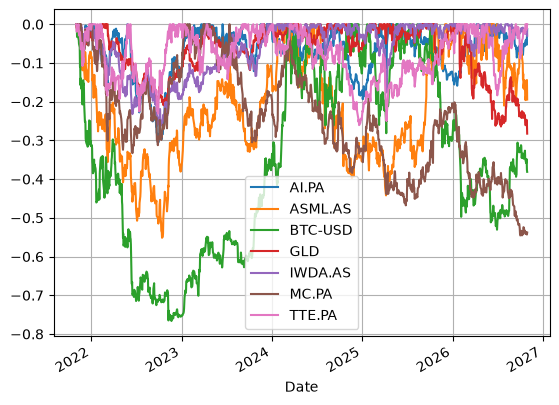


=== Max drawdown (data over 5 years)===

Bitcoin USD : -76.63%
ASML HOLDING : -55.15%
LVMH : -54.55%
AIR LIQUIDE : -30.57%
SPDR Gold Shares : -28.26%
iShares Core MSCI World UCITS E : -26.13%
TOTALENERGIES : -26.05%


In [16]:
def compute_drawdown(prices) :
    return prices / prices.cummax() - 1

drawdown = compute_drawdown(df)
max_drawdown = drawdown.min()

drawdown.plot(grid=True)
plt.show()

print(f"\n=== Max drawdown (data over {round(n_years)} years)===\n")
for ticker, drawdown in max_drawdown.sort_values(ascending=True).items():
    name = name_by_ticker[ticker]
    print(f"{name} : {round(drawdown*100, 2)}%")



## Summary
The table brings together the main indicators, sorted by return / risk ratio.
The chart compares annualised return and volatility: assets towards the top left offer more return for less risk.

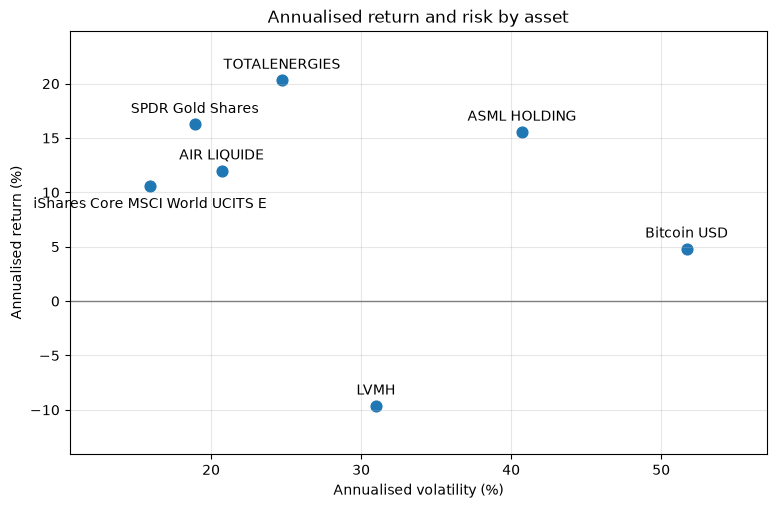

,Total return (%),Annual return (%),Annual volatility (%),Ratio,Max drawdown (%)
SPDR Gold Shares,112.380605,16.279639,18.905153,0.861122,-28.255696
TOTALENERGIES,152.163235,20.347051,24.727414,0.822854,-26.052293
iShares Core MSCI World UCITS E,65.408853,10.602685,15.935514,0.665349,-26.134045
AIR LIQUIDE,76.182701,12.009107,20.706052,0.579981,-30.566118
ASML HOLDING,106.024596,15.574297,40.723233,0.382443,-55.152748
Bitcoin USD,26.545303,4.827308,51.694637,0.093381,-76.634564
LVMH,-39.627981,-9.611523,31.001853,-0.310031,-54.549741


In [17]:

summary = pd.DataFrame({
    "Total return (%)": total_returns * 100,
    "Annual return (%)": annual_return * 100,
    "Annual volatility (%)": annual_volatility * 100,
    "Ratio": return_vol_ratio,
    "Max drawdown (%)": max_drawdown * 100,
})

summary = summary.rename(index=name_by_ticker)
summary = summary.sort_values("Ratio", ascending=False)

summary.round(2)
labels_below = ["iShares Core MSCI World UCITS E"]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(summary["Annual volatility (%)"], summary["Annual return (%)"], s=60)

for name, row in summary.iterrows():
    offset = (0, -16) if name in labels_below else (0, 8)
    ax.annotate(name, (row["Annual volatility (%)"], row["Annual return (%)"]),
                xytext=offset, textcoords="offset points", ha="center")

ax.axhline(0, color="grey", linewidth=1)
ax.set_title("Annualised return and risk by asset")
ax.set_xlabel("Annualised volatility (%)")
ax.set_ylabel("Annualised return (%)")
ax.grid(alpha=0.3)
ax.margins(x=0.15, y=0.15)
plt.show()

summary


## Conclusion